In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.datasets import mnist

(X_train, _), (X_test, y_test) = mnist.load_data()
X_train = X_train.astype("float32").reshape(-1, 784) / 255.0
X_test = X_test.astype("float32").reshape(-1, 784) / 255.0
print(X_train.shape, X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 784) (10000, 784)


In [2]:
encoding_dim = 32
input_img = Input(shape=(784,))
x = Dense(128, activation="relu")(input_img)
x = Dense(64, activation="relu")(x)
latent = Dense(encoding_dim, activation="relu")(x)
x = Dense(64, activation="relu")(latent)
x = Dense(128, activation="relu")(x)
decoded = Dense(784, activation="sigmoid")(x)

autoencoder = Model(input_img, decoded)
encoder_ae = Model(input_img, latent)
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

history_ae = autoencoder.fit(
    X_train, X_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test, X_test)
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2466 - val_loss: 0.1705
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.1532 - val_loss: 0.1383
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1331 - val_loss: 0.1265
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1244 - val_loss: 0.1193
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.1181 - val_loss: 0.1146
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.1141 - val_loss: 0.1108
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1109 - val_loss: 0.1082
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1084 - val_loss: 0.1059
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1064 - val_loss: 0.1043
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.1047 - val_loss: 0.1025


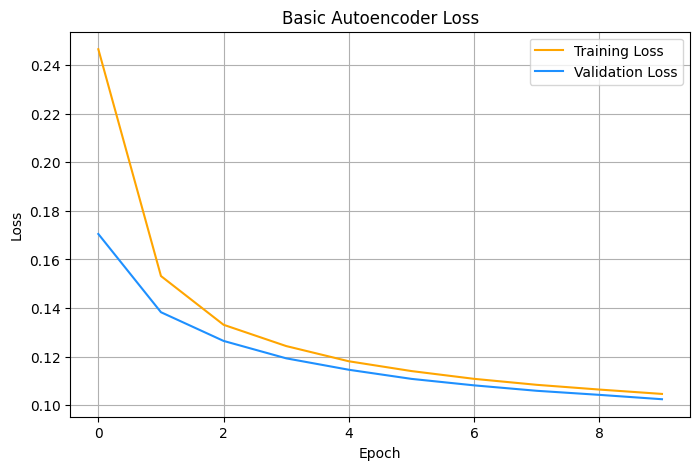

Latent Feature Shape: (10000, 32)
Original Dimension : 784
Compressed Dimension : 32
Compression Ratio : 24.5


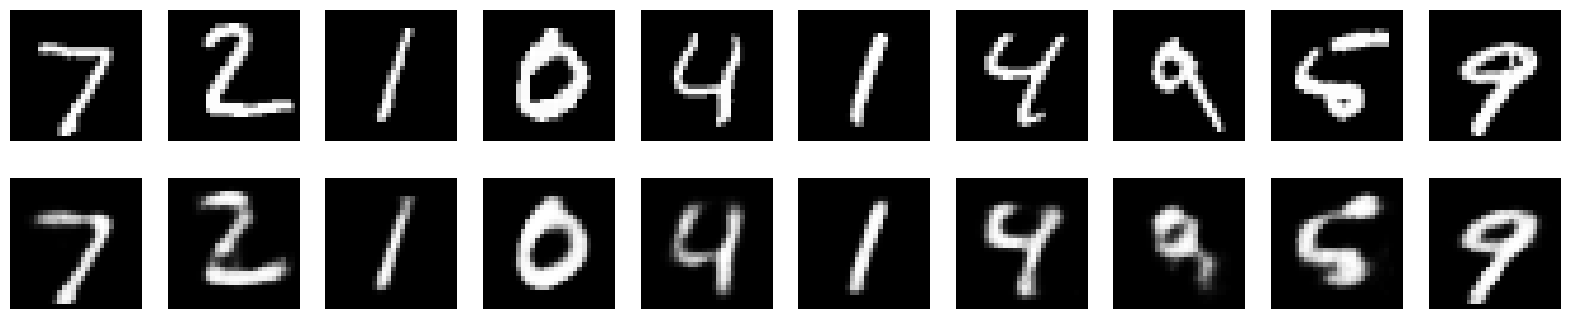

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(history_ae.history["loss"], color="#FFA500", label="Training Loss")
plt.plot(history_ae.history["val_loss"], color="dodgerblue", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic Autoencoder Loss")
plt.legend()
plt.grid(True)
plt.show()

recon_ae = autoencoder.predict(X_test, verbose=0)
latent_features = encoder_ae.predict(X_test, verbose=0)
print("Latent Feature Shape:", latent_features.shape)
print("Original Dimension :", 784)
print("Compressed Dimension :", encoding_dim)
print("Compression Ratio :", 784 / encoding_dim)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(recon_ae[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.show()

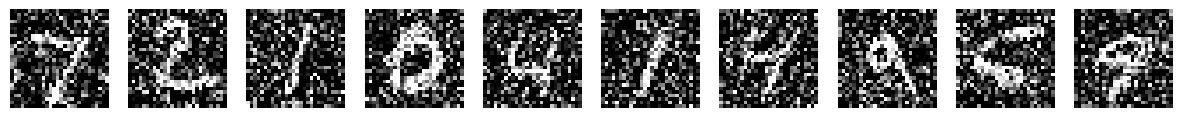

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 0.2650 - val_loss: 0.2071
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.1828 - val_loss: 0.1657
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.1607 - val_loss: 0.1537
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1512 - val_loss: 0.1472
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1456 - val_loss: 0.1421
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1414 - val_loss: 0.1389
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1383 - val_loss: 0.1365
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1356 - val_loss: 0.1338
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1332 - val_loss: 0.1316
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1312 - val_loss: 0.1295


In [4]:
noise_factor = 0.5
X_train_noisy = np.clip(X_train + noise_factor * np.random.normal(size=X_train.shape), 0.0, 1.0)
X_test_noisy = np.clip(X_test + noise_factor * np.random.normal(size=X_test.shape), 0.0, 1.0)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test_noisy[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.show()

inp = Input(shape=(784,))
x = Dense(128, activation="relu")(inp)
x = Dense(64, activation="relu")(x)
enc = Dense(encoding_dim, activation="relu")(x)
x = Dense(64, activation="relu")(enc)
x = Dense(128, activation="relu")(x)
out = Dense(784, activation="sigmoid")(x)

dae = Model(inp, out)
dae.compile(optimizer="adam", loss="binary_crossentropy")
dae.summary()

history_dae = dae.fit(
    X_train_noisy, X_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test_noisy, X_test)
)

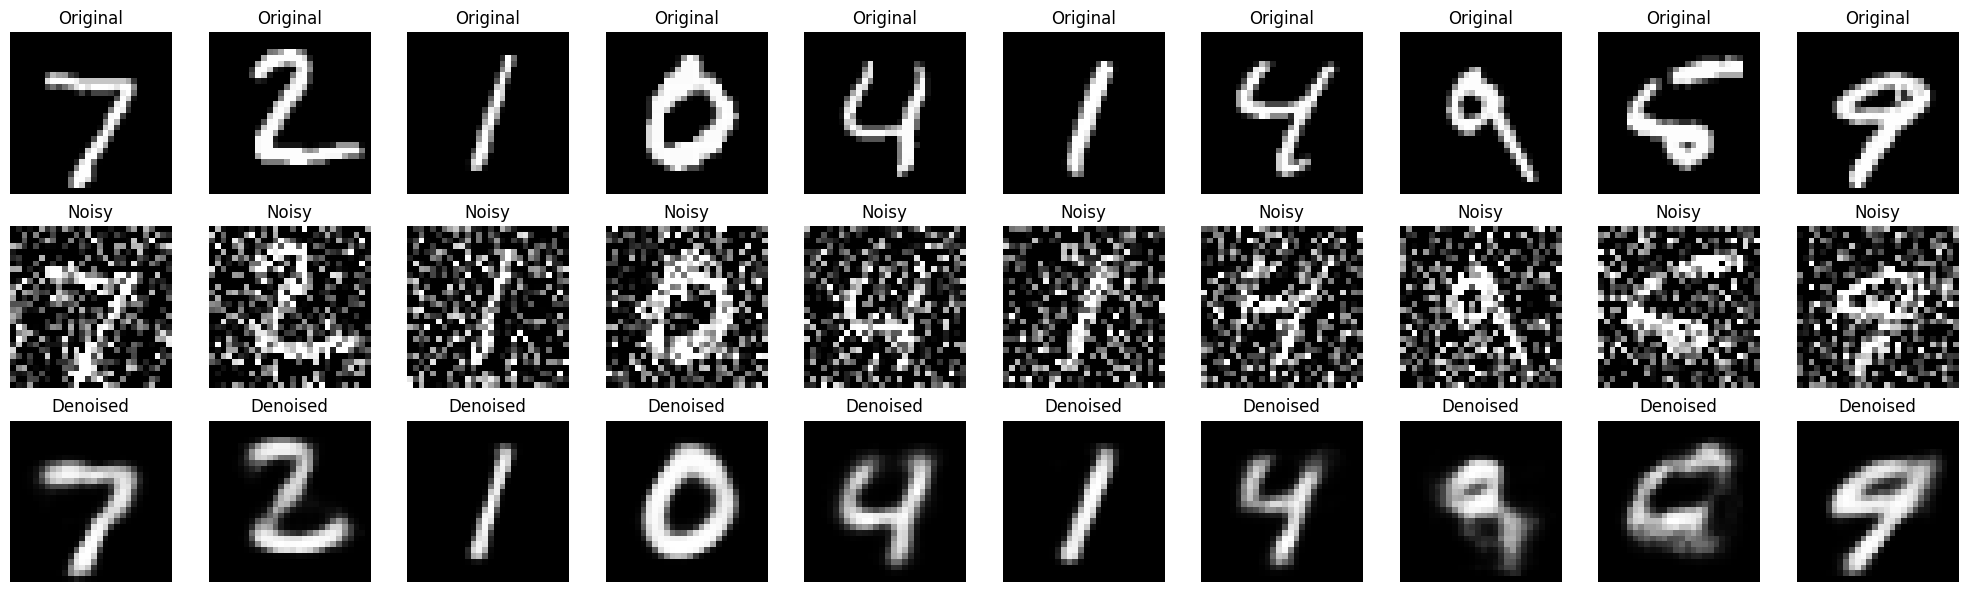

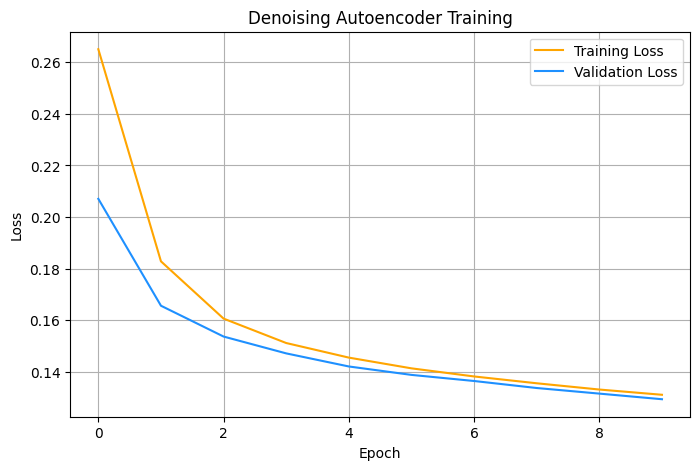

In [5]:
denoised = dae.predict(X_test_noisy, verbose=0)

n = 10
plt.figure(figsize=(20, 6))
for i in range(n):
    plt.subplot(3, n, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(X_test_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")
    plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_dae.history["loss"], color="#FFA500", label="Training Loss")
plt.plot(history_dae.history["val_loss"], color="dodgerblue", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Denoising Autoencoder Training")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
input_dim, hidden_dim, latent_dim = 784, 256, 2
kl_weight = 1.0
epochs = 20

inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(hidden_dim, activation="relu")(inputs)
z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

z = Sampling()([z_mean, z_log_var])
encoder = Model(inputs, [z_mean, z_log_var, z])

latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(hidden_dim, activation="relu")(latent_inputs)
outputs = layers.Dense(input_dim, activation="sigmoid")(x)
decoder = Model(latent_inputs, outputs)

class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            recon = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(data, recon)) * input_dim
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            total_loss = reconstruction_loss + kl_weight * kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return {"loss": total_loss,
                "reconstruction_loss": reconstruction_loss,
                "kl_loss": kl_loss}

vae = VAE(encoder, decoder)
vae.compile(optimizer="adam")
history_vae = vae.fit(X_train, epochs=epochs, batch_size=256, verbose=1)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - kl_loss: 4.4473 - loss: 183.5283 - reconstruction_loss: 179.0810 
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - kl_loss: 3.4744 - loss: 176.4569 - reconstruction_loss: 172.9825
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - kl_loss: 3.4593 - loss: 167.1465 - reconstruction_loss: 163.6872
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - kl_loss: 3.0069 - loss: 173.5127 - reconstruction_loss: 170.5058
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - kl_loss: 3.3308 - loss: 167.4284 - reconstruction_loss: 164.0976
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - kl_loss: 3.2556 - loss: 168.4515 - reconstruction_loss: 165.1959
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - kl_loss: 3.3214 - loss: 165.3204 - reconstruction_loss: 161.9990
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - kl_loss: 3.4112 - loss: 150.4668 - reconstruction_loss: 147.0556
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━

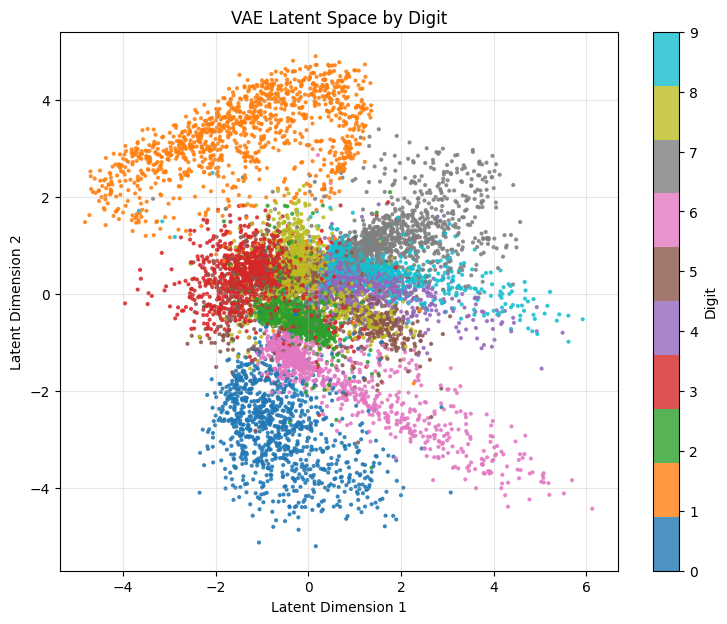

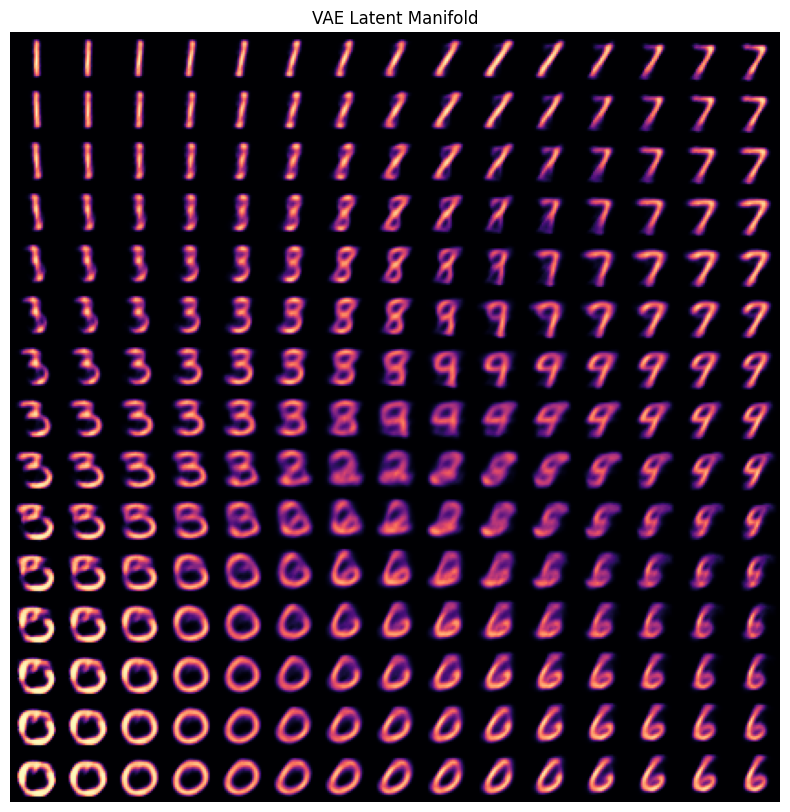

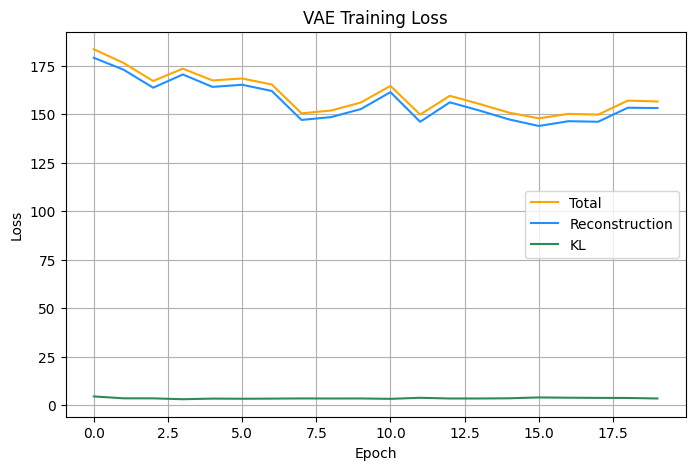

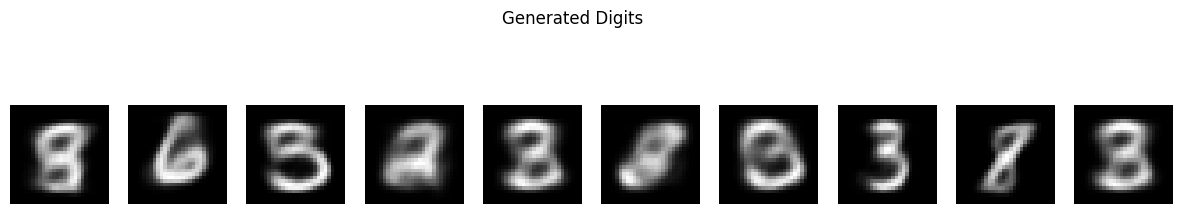

In [7]:
z_m, _, _ = encoder.predict(X_test, verbose=0)
plt.figure(figsize=(9, 7))
sc = plt.scatter(z_m[:, 0], z_m[:, 1], c=y_test, cmap="tab10", s=4, alpha=0.8)
plt.colorbar(sc, ticks=range(10), label="Digit")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space by Digit")
plt.grid(alpha=0.3)
plt.show()

n = 15
grid = np.linspace(-3, 3, n)
zs = np.array([[xi, yi] for yi in grid[::-1] for xi in grid], dtype="float32")
imgs = decoder.predict(zs, verbose=0).reshape(n, n, 28, 28)
canvas = imgs.transpose(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(10, 10))
plt.imshow(canvas, cmap="magma")
plt.axis("off")
plt.title("VAE Latent Manifold")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_vae.history["loss"], color="#FFA500", label="Total")
plt.plot(history_vae.history["reconstruction_loss"], color="dodgerblue", label="Reconstruction")
plt.plot(history_vae.history["kl_loss"], color="seagreen", label="KL")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True)
plt.show()

gen = decoder.predict(tf.random.normal((10, latent_dim)), verbose=0)
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(gen[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Generated Digits")
plt.show()

In [8]:
comparison = pd.DataFrame({
    "Model": ["Basic Autoencoder", "Denoising Autoencoder", "Variational Autoencoder"],
    "Purpose": ["Compression & Feature Extraction", "Image Denoising", "Image Generation"],
    "Latent Space": ["Deterministic", "Deterministic", "Probabilistic"]
})
comparison

,Model,Purpose,Latent Space
0,Basic Autoencoder,Compression & Feature Extraction,Deterministic
1,Denoising Autoencoder,Image Denoising,Deterministic
2,Variational Autoencoder,Image Generation,Probabilistic


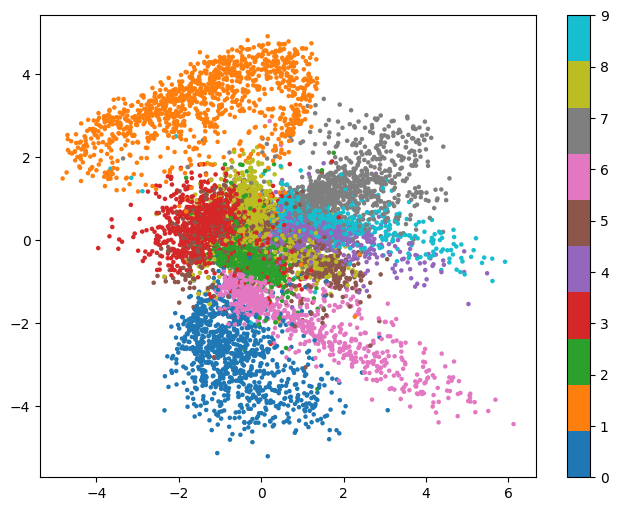

In [9]:
z_m, _, _ = encoder.predict(X_test, verbose=0)
plt.figure(figsize=(8, 6))
plt.scatter(z_m[:, 0], z_m[:, 1], c=y_test, cmap="tab10", s=5)
plt.colorbar()
plt.show()